In [1]:
%%bash
mkdir -p frames
if [ -z "$( ls -A 'frames' )" ]; then
    ffmpeg -i original.mp4 -vf fps=24 frames/frame%04d.png
else
    echo Frames folder not empty, skipping
fi

Frames folder not empty, skipping


In [2]:
HEIGHT = 12
WIDTH = 180
FRAMES = 5258 # 5258
FPS = 1 # 24
MODE = 3 # 1 for sequence per frame, 2 for sequence per coordinate, 3 for sequence per line

In [3]:
!mkdir -p queries
!rm queries/*.fa
!rm queries/*.json
from query_generator import *
if MODE == 1:
    generate_queries_by_frame(HEIGHT, WIDTH, FRAMES, FPS)
elif MODE == 2:
    generate_queries_by_coordinate(HEIGHT, WIDTH, FRAMES, FPS)
elif MODE == 3:
    generate_queries_by_line(HEIGHT, WIDTH, FRAMES, FPS)

Done with 1956 unique lines!                                                  


In [4]:
%%writefile custom.matrix
   A  C  G  T
A  1  1 -2 -2
C  1  1 -2 -2
G -2 -2  1  1
T -2 -2  1  1

Overwriting custom.matrix


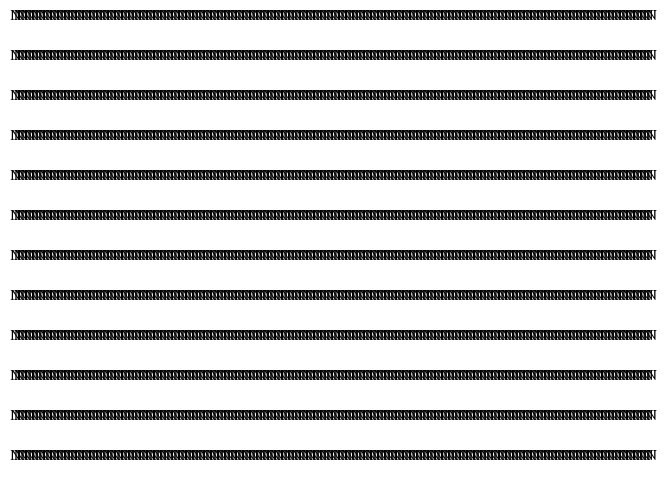

In [5]:
def get_sequence(data):
    if data["status"] != "Sequence found":
        return ""
    s = data["sequence"]
    if data["rev-comp"]:
        s = s[::-1].replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

sequences = {}

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

plt.rcParams['font.family'] = 'STIXGeneral'

fig, ax = plt.subplots()
ax.axis("off")

fig_text = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        fig_text[(x, y)] = fig.text(x/WIDTH, 1-y/HEIGHT, "N")
        
plt.tight_layout()
        
def clear():
    for tx in fig_text.values():
        tx.set_text("-")
        tx.set_color((0,0,0))

def draw(i):
    if MODE == 1:
        if sequences[i] == "":
            return
        print(f"Drawing frame {i} in frame mode", end="\r", flush=True)
        remainder = len(sequences[i]) % WIDTH
        pad_width = (WIDTH - remainder) % WIDTH
        sequence = np.pad(np.array(list(sequences[i])), (0, pad_width), mode='constant', constant_values='-').reshape((-1, WIDTH))
        for x in range(WIDTH):
            for y in range(HEIGHT):
                base = sequence[y,x]
                color = (1,0,0) if base in "AG" else (0,0,1) if base in "CT" else (0,0,0)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
    elif MODE == 2:
        print(f"Drawing frame {i} in coordinate mode", end="\r", flush=True)
        for x, y in fig_text.keys():
            sequence = sequences[(x, y)]
            if sequence != "":
                base = sequence[i] if i<len(sequence) else '-'
                color = (1,0,0) if base in "AG" else (0,0,1) if base in "CT" else (0,0,0)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
    elif MODE == 3:
        print(f"Drawing frame {i} in line mode", end="\r", flush=True)
        if i not in sequences:
              return
        sequence = np.array(list(sequences[i])).reshape((HEIGHT, WIDTH))
        for x in range(WIDTH):
            for y in range(HEIGHT):
                base = sequence[y,x]
                color = (1,0,0) if base in "AG" else (0,0,1) if base in "CT" else (0,0,0)
                fig_text[(x, y)].set_text(base)
                fig_text[(x, y)].set_color(color)
        
                

In [6]:
# Sample
if MODE == 1:
    sample_frame = "3217"
    !glsearch36 -s custom.matrix -b 1 -d 1 queries/query_{sample_frame}.fa chr1.fna > sample.output

In [7]:
# Sample
if MODE == 1:
    from IPython.display import Image
    Image(filename=f'frames/frame{sample_frame}.png')

In [8]:
# Sample
if MODE == 1:
    with open(f"queries/query_{sample_frame}.fa", "r") as f:
        f.readline()
        sequences[-2] = f.readline()
    draw(-2)
    sequences.pop(-2)
    fig

In [9]:
if MODE == 1:
    clear()

In [10]:
# Sample
if MODE == 1:
    from output_parser import parse
    sequences[-1] = get_sequence(parse("sample.output"))
    draw(-1)
    sequences.pop(-1)
    fig

In [11]:
if MODE == 1:
    clear()

In [ ]:
%%bash
mkdir -p outputs
. align.sh

===
Aligning to queries/query_0000.fa
Succeeded in finding alignment in 192 seconds to outputs/fasta_0000.output
Successes: 1, Fails: 0
Total time: 192, Count: 1, Average time: 192
===
Aligning to queries/query_0001.fa
Succeeded in finding alignment in 179 seconds to outputs/fasta_0001.output
Successes: 2, Fails: 0
Total time: 371, Count: 2, Average time: 185
===
Aligning to queries/query_0002.fa
Succeeded in finding alignment in 166 seconds to outputs/fasta_0002.output
Successes: 3, Fails: 0
Total time: 537, Count: 3, Average time: 179
===
Aligning to queries/query_0003.fa
Succeeded in finding alignment in 164 seconds to outputs/fasta_0003.output
Successes: 4, Fails: 0
Total time: 701, Count: 4, Average time: 175
===
Aligning to queries/query_0004.fa
Succeeded in finding alignment in 164 seconds to outputs/fasta_0004.output
Successes: 5, Fails: 0
Total time: 865, Count: 5, Average time: 173
===
Aligning to queries/query_0005.fa
Succeeded in finding alignment in 157 seconds to outputs/

In [ ]:
from output_parser import parse_to_json_files
parse_to_json_files()

In [ ]:
import glob
import json

data = {}

if MODE == 1:
    i = 0
    for filename in glob.glob("outputs/fasta_*.json"):
        with open(filename, "r") as f:
            data[i] = json.loads(f.read())
        i += 1
    print(len(data), "files loaded")
    
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            try:
                with open(f"outputs/fasta_{y:02d}_{x:02d}.json", "r") as f:
                    data[(x, y)] = json.loads(f.read())
            except FileNotFoundError:
                    data[(x, y)] = {"status": "File not found"}
    print(len(data), "files loaded")
    
elif MODE == 3:
    line_cache = {}
    for filename in glob.glob("outputs/fasta_*.json"):
        index = int(filename[14:-5])
        with open(filename, "r") as f:
            line_cache[index] = json.loads(f.read())
    data['cache'] = line_cache
    data['frames'] = {}
    for filename in glob.glob("queries/frame_*.json"):
        index = int(filename[14:-5])
        with open(filename, "r") as f:
            data['frames'][index] = json.loads(f.read())
    print(len(data['cache']) + len(data['frames']), "files loaded")
    

In [ ]:
sequences = {}

if MODE == 1:
    for i in range(len(data)):
        sequences[i] = get_sequence(data[i])
    print(sequences[0])
elif MODE == 2:
    for x in range(WIDTH):
        for y in range(HEIGHT):
            sequences[(x, y)] = get_sequence(data[(x, y)])
    print(sequences[(0, 0)])
elif MODE == 3:
    line_cache = {}
    for line in sorted(data['cache'].keys()):
        line_cache[line] = get_sequence(data['cache'][line])
    frames = sorted(data['frames'].keys())
    for i in range(len(frames)):
        if 'lines' in data['frames'][frames[i]]:
            s = ""
            for line in data['frames'][frames[i]]['lines']:
                if line in line_cache:
                    s += line_cache[line]
                else:
                    s += "N" * WIDTH
            sequences[i] = s + ("N" * (HEIGHT * WIDTH - len(s)))
        else:
            sequences[i] = "N" * (HEIGHT * WIDTH)
            

In [ ]:
ani = animation.FuncAnimation(fig=fig, func=draw, frames=FRAMES*FPS//24, interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS)
ani.save('animation.mp4', writer=FFwriter)
fig

In [ ]:
from moviepy import VideoFileClip, clips_array

clip1 = VideoFileClip("original.mp4")
clip2 = VideoFileClip("animation.mp4")

final_clip = clips_array([[clip1, clip2]])

final_clip.write_videofile("final.mp4", fps=24)

In [ ]:
from IPython.display import Video
Video("final.mp4")

In [ ]:
del ani
plt.close(fig)